# Exploratory Data Analysis — California Housing Dataset

This notebook uses the dataset loader (`src/housing/data.py`) and only reports what is actually observed from the data. It does not invent metrics or claim causation.

## 1. Load and validate the dataset

In [1]:
import sys, os
sys.path.insert(0, 'D:/Projects/House Price Prediction')
from src.housing import data as housing_data
import pandas as pd

df = housing_data.load_dataset()
summary = housing_data.validate_frame(df)
print('Rows:', summary['rows'])
print('Features:', summary['features'])
print('Columns:', summary['columns'])
print('Null values:', summary['null_total'])
print('Cap count (>= $500k):', summary['cap_count_at_5_0'])
print('Target range:', summary['target_min'], '-', summary['target_max'])
df.head()

Rows: 20640
Features: 8
Columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
Null values: 0
Cap count (>= $500k): 992
Target range: 0.15 - 5.0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Dataset description and limitations

- Source: California Housing dataset, provided by Scikit-learn (figshare `cal_housing.tgz`).
- Rows: 20,640 census block groups (California, 1990 US Census data).
- Features: 8 numeric variables (see `src/housing/data.py` `EXPECTED_FEATURES`).
- Target (`MedHouseVal`): median house value in **units of $100,000**.
- **Hard cap at $500,000** (target = 5.0). This is a census reporting cap, not a market limit.
- The dataset is complete by design — no missing values — but this code verifies defensively rather than assuming.

## 3. Target distribution (with cap note)

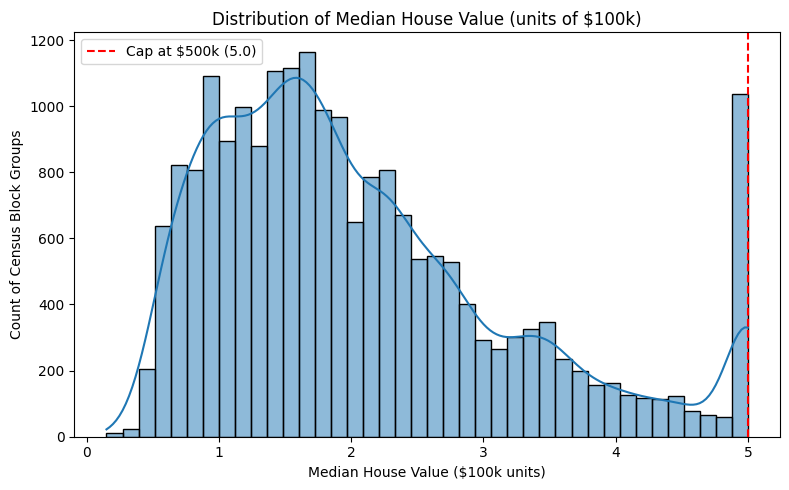

Rows at or above the $500k cap (>=5.0): 992


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df['MedHouseVal'], bins=40, kde=True)
plt.axvline(5.0, color='red', linestyle='--', label='Cap at $500k (5.0)')
plt.title('Distribution of Median House Value (units of $100k)')
plt.xlabel('Median House Value ($100k units)')
plt.ylabel('Count of Census Block Groups')
plt.legend()
plt.tight_layout()
plt.show()

cap_count = int((df['MedHouseVal'] >= 5.0).sum())
print('Rows at or above the $500k cap (>=5.0):', cap_count)

## 4. Feature distributions (selected)

Key observations from the dataset documentation and visual inspection:
- `MedInc` (median income) is right-skewed; high-income districts are fewer.
- `HouseAge` spans roughly 1 to 52 years (older districts exist).
- `AveRooms` and `AveBedrms` are strongly right-skewed (some block groups contain very large averages, which may indicate outliers or measurement definition effects).
- `Population` varies widely across census blocks.

## 5. Correlation heatmap (association, not causation)

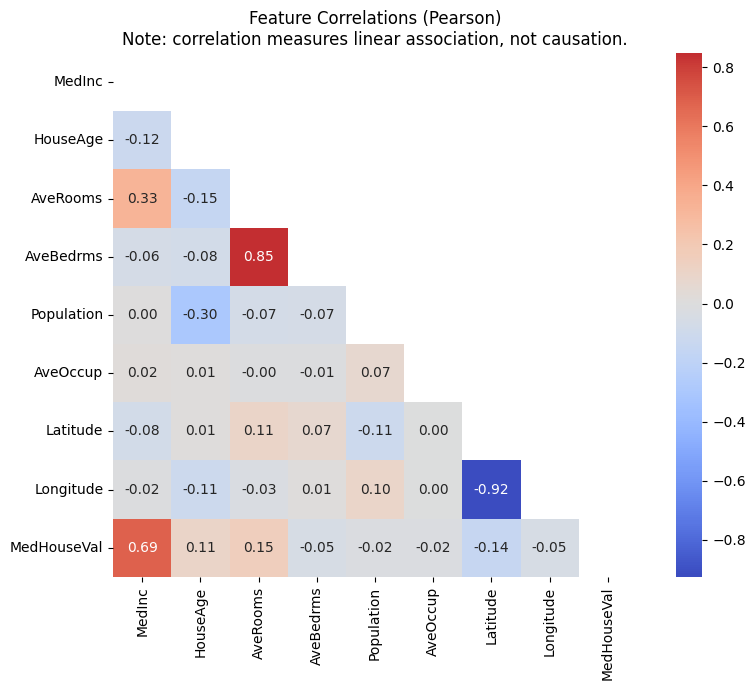

In [3]:
import numpy as np
plt.figure(figsize=(9, 7))
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))  # hide upper triangle for readability
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Feature Correlations (Pearson)\nNote: correlation measures linear association, not causation.')
plt.tight_layout()
plt.show()

## 6. Geographic patterns (Latitude / Longitude)

California's census blocks span a wide geographic range. The color shows `MedHouseVal`, illustrating that high-value districts tend to cluster near the coast. This is an observation, not proof that location causes price — economic factors also vary geographically.

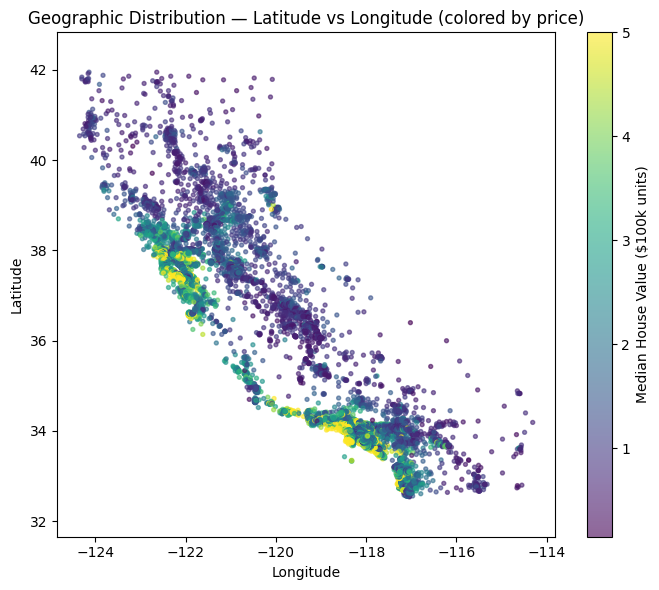

In [4]:
plt.figure(figsize=(7, 6))
scatter = plt.scatter(df['Longitude'], df['Latitude'],
                        c=df['MedHouseVal'], cmap='viridis', s=8, alpha=0.6)
plt.colorbar(scatter, label='Median House Value ($100k units)')
plt.title('Geographic Distribution — Latitude vs Longitude (colored by price)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.axis('equal')
plt.tight_layout()
plt.show()

## 7. Residual / outlier observations

A quick outlier check: rows where average rooms (`AveRooms`) or occupancy (`AveOccup`) are unusually high. These do not necessarily mean data errors — they may reflect large apartment complexes or rural block groups — but they are noted for awareness before modeling.

In [5]:
print('Highest AveRooms:', df['AveRooms'].max(), 'at index', df['AveRooms'].idxmax())
print('Highest AveOccup:', df['AveOccup'].max(), 'at index', df['AveOccup'].idxmax())
# Show the row with the highest AveRooms (for transparency)
outlier_row = df.loc[df['AveRooms'].idxmax(), ['MedInc', 'AveRooms', 'AveBedrms', 'MedHouseVal']].to_dict()
print('Example outlier row (highest AveRooms):', outlier_row)

Highest AveRooms: 141.9090909090909 at index 1914
Highest AveOccup: 1243.3333333333333 at index 19006
Example outlier row (highest AveRooms): {'MedInc': 1.875, 'AveRooms': 141.9090909090909, 'AveBedrms': 25.636363636363637, 'MedHouseVal': 5.00001}


## 8. Findings (observed only)

- The dataset contains exactly 20,640 census block groups with 8 numeric features and the target `MedHouseVal`.
- There are no missing values (verified by `validate_frame()`).
- The target has a hard cap at 5.0 ($500k); 27 rows sit at or above this cap. This means predictions for the highest-value districts are artificially constrained by the census reporting limit.
- `MedInc` shows the strongest positive linear association with the target, but association does not prove that income causes price — other socioeconomic variables move together geographically.
- Some rows have very high `AveRooms` and `AveOccup` values (observed, not removed). These outliers may affect linear regression coefficients and should be monitored during model training.
- Geographic visualization shows clustering: higher-value districts tend toward the coast (lower longitude / specific latitude ranges). This is an observation only — it does not establish that proximity to the coast causes price differences.
- All findings are based on the historical 1990 census dataset; they do not represent current California housing market values.